In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import display


In [2]:
pd.set_option('display.max_columns', None)

In [3]:
df = pd.read_csv("data/speeches_with_text.csv")
df.columns = df.columns.str.lower()
df["text_len"] = df["text_span"].fillna("").str.len()
df["year_int"] = pd.to_numeric(df["year"], errors="coerce").astype("Int64")


In [4]:
df

,speech_id,speaker_uid,speaker_first_name,speaker_last_name,speaker_fullname,party,party_name,gender,source_name,source_abbrev,meeting_uid,meeting_number,meeting_datetime,meeting_date,session_name,year,legislative_period_uid,debate_id,bill_number,bill_title_de,bill_title_fr,bill_labels,discussion_id,partition_id,paragraph_id,name,role,language_of_text,text_span,text_len,year_int
0,81893,453.0,André,Bugnon,Bugnon André,SVP,Schweizerische Volkspartei,m,Online DB,ODB,941.0,12.0,2007-12-20T08:00:00.000000000,2007-12-20,Winter session,2007.0,48.0,06_405.5,6.405,Verdoppelung der Anzahl Durchdiener,Doublement de la proportion de militaires en s...,Bill|Parliamentary Initiative,12870.0,12870.1,1,Bugnon André,President,FR,La commission propose de ne pas donner suite à...,60,2007
1,81893,453.0,André,Bugnon,Bugnon André,SVP,Schweizerische Volkspartei,m,Online DB,ODB,941.0,12.0,2007-12-20T08:00:00.000000000,2007-12-20,Winter session,2007.0,48.0,06_405.5,6.405,Verdoppelung der Anzahl Durchdiener,Doublement de la proportion de militaires en s...,Bill|Parliamentary Initiative,12870.0,12870.1,2,Bugnon André,President,FR,[VS],4,2007
2,81893,453.0,André,Bugnon,Bugnon André,SVP,Schweizerische Volkspartei,m,Online DB,ODB,941.0,12.0,2007-12-20T08:00:00.000000000,2007-12-20,Winter session,2007.0,48.0,06_405.5,6.405,Verdoppelung der Anzahl Durchdiener,Doublement de la proportion de militaires en s...,Bill|Parliamentary Initiative,12870.0,12870.1,3,Bugnon André,President,FR,Angenommen - Adopté,19,2007
3,81894,390.0,Hans,Widmer,Widmer Hans,SP,Sozialdemokratische Partei der Schweiz,m,Online DB,ODB,941.0,12.0,2007-12-20T08:00:00.000000000,2007-12-20,Winter session,2007.0,48.0,06_405.5,6.405,Verdoppelung der Anzahl Durchdiener,Doublement de la proportion de militaires en s...,Bill|Parliamentary Initiative,12870.0,12870.1,1,Widmer Hans,For the committee,DE,"Ich möchte Sie nur nochmals bitten, das Result...",481,2007
4,81894,390.0,Hans,Widmer,Widmer Hans,SP,Sozialdemokratische Partei der Schweiz,m,Online DB,ODB,941.0,12.0,2007-12-20T08:00:00.000000000,2007-12-20,Winter session,2007.0,48.0,06_405.5,6.405,Verdoppelung der Anzahl Durchdiener,Doublement de la proportion de militaires en s...,Bill|Parliamentary Initiative,12870.0,12870.1,2,Widmer Hans,For the committee,DE,"In diesem Sinne bitte ich Sie nochmals, den An...",79,2007
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
666686,288682,3912.0,Christian,Wasserfallen,Wasserfallen Christian,FDP-Liberale,FDP.Die Liberalen,m,Online DB,ODB,4518.0,9.0,2021-09-23T08:00:00.000000000,2021-09-23,Fall session,2021.0,51.0,21_049.1,21.049,Gentechnikgesetz. Änderung,Loi sur le génie génétique. Modification,Bill|Federal Council Dispatch,54270.0,54270.1,8,Wasserfallen Christian,NaN,DE,Noch etwas zur Technologie: Es grenzt an Absur...,540,2021
666687,288682,3912.0,Christian,Wasserfallen,Wasserfallen Christian,FDP-Liberale,FDP.Die Liberalen,m,Online DB,ODB,4518.0,9.0,2021-09-23T08:00:00.000000000,2021-09-23,Fall session,2021.0,51.0,21_049.1,21.049,Gentechnikgesetz. Änderung,Loi sur le génie génétique. Modification,Bill|Federal Council Dispatch,54270.0,54270.1,9,Wasserfallen Christian,NaN,DE,Die jüngst erschienene Befragung zeigt deutlic...,429,2021
666688,288682,3912.0,Christian,Wasserfallen,Wasserfallen Christian,FDP-Liberale,FDP.Die Liberalen,m,Online DB,ODB,4518.0,9.0,2021-09-23T08:00:00.000000000,2021-09-23,Fall session,2021.0,51.0,21_049.1,21.049,Gentechnikgesetz. Änderung,Loi sur le génie génétique. Modification,Bill|Federal Council Dispatch,54270.0,54270.1,10,Wasserfallen Christian,NaN,DE,"Lange Forschung und Rede, kurzer Sinn: In eine...",659,2021
666689,288682,3912.0,Christian,Wasserfallen,Wasserfallen Christian,FDP-Liberale,FDP.Die Liberalen,m,Online DB,ODB,4518.0,9.0,2021-09-23T08:00:00.000000000,2021-09-23,Fall session,2021.0,51.0,21_049.1,21.049,Gentechnikgesetz. Änderung,Loi sur le génie génétique. Modification,Bill|Federal Council

13.0740    4244
16.0770    3884
17.0710    3588

In [21]:
df[df['bill_number'].isin([13.0740, 16.0770, 17.0710])]

,speech_id,speaker_uid,speaker_first_name,speaker_last_name,speaker_fullname,party,party_name,gender,source_name,source_abbrev,meeting_uid,meeting_number,meeting_datetime,meeting_date,session_name,year,legislative_period_uid,debate_id,bill_number,bill_title_de,bill_title_fr,bill_labels,discussion_id,partition_id,paragraph_id,name,role,language_of_text,text_span,text_len,year_int
3283,178106,3912.0,Christian,Wasserfallen,Wasserfallen Christian,FDP-Liberale,FDP.Die Liberalen,m,Online DB,ODB,1923.0,8.0,2014-12-04T08:00:00.000000000,2014-12-04,Winter session,2014.0,49.0,13_074.1,13.074,"Energiestrategie 2050, erstes Massnahmenpaket....","Stratégie énergétique 2050, premier volet. Pou...",Bill|Federal Council Dispatch,32138.0,32138.8,1,Wasserfallen Christian,NaN,DE,"Frau Bundesrätin, ich habe Ihr Argument gegen ...",245,2014
3284,178106,3912.0,Christian,Wasserfallen,Wasserfallen Christian,FDP-Liberale,FDP.Die Liberalen,m,Online DB,ODB,1923.0,8.0,2014-12-04T08:00:00.000000000,2014-12-04,Winter session,2014.0,49.0,13_074.1,13.074,"Energiestrategie 2050, erstes Massnahmenpaket....","Stratégie énergétique 2050, premier volet. Pou...",Bill|Federal Council Dispatch,32138.0,32138.8,2,Wasserfallen Christian,NaN,DE,"Sie haben vorhin auch gesagt, die Befreiungsmö...",453,2014
3326,178107,488.0,Doris,Leuthard,Leuthard Doris,CVP,Christlichdemokratische Volkspartei der Schweiz,f,Online DB,ODB,1923.0,8.0,2014-12-04T08:00:00.000000000,2014-12-04,Winter session,2014.0,49.0,13_074.1,13.074,"Energiestrategie 2050, erstes Massnahmenpaket....","Stratégie énergétique 2050, premier volet. Pou...",Bill|Federal Council Dispatch,32138.0,32138.8,1,Leuthard Doris,Member of the federal council,DE,Es ist schon ein Unterschied: Die Enaw hat etw...,878,2014
3548,178108,1279.0,Roger,Nordmann,Nordmann Roger,SP,Sozialdemokratische Partei der Schweiz,m,Online DB,ODB,1923.0,8.0,2014-12-04T08:00:00.000000000,2014-12-04,Winter session,2014.0,49.0,13_074.1,13.074,"Energiestrategie 2050, erstes Massnahmenpaket....","Stratégie énergétique 2050, premier volet. Pou...",Bill|Federal Council Dispatch,32138.0,32138.8,1,Nordmann Roger,For the committee,FR,S'agissant de la modification de la loi sur le...,504,2014
3549,178108,1279.0,Roger,Nordmann,Nordmann Roger,SP,Sozialdemokratische Partei der Schweiz,m,Online DB,ODB,1923.0,8.0,2014-12-04T08:00:00.000000000,2014-12-04,Winter session,2014.0,49.0,13_074.1,13.074,"Energiestrategie 2050, erstes Massnahmenpaket....","Stratégie énergétique 2050, premier volet. Pou...",Bill|Federal Council Dispatch,32138.0,32138.8,2,Nordmann Roger,For the committee,FR,Je vous invite à accepter la proposition de la...,186,2014
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
658397,239448,3871.0,Pirmin,Bischof,Bischof Pirmin,Mitte,Die Mitte,m,Online DB,ODB,4140.0,9.0,2018-12-11T08:05:00.000000000,2018-12-11,Winter session,2018.0,50.0,16_077.2,16.077,OR. Aktienrecht,CO. Droit de la société anonyme,Bill|Federal Council Dispatch,44960.0,44960.1,8,Bischof Pirmin,NaN,DE,"Ich bitte Sie, dem Nichteintretensantrag Noser...",59,2018
658408,239449,4112.0,Thomas,Minder,Minder Thomas,parteilos,parteilos,m,Online DB,ODB,4140.0,9.0,2018-12-11T08:05:00.000000000,2018-12-11,Winter session,2018.0,50.0,16_077.2,16.077,OR. Aktienrecht,CO. Droit de la société anonyme,Bill|Federal Council Dispatch,44960.0,44960.1,1,Minder Thomas,NaN,DE,"Ich ziehe meinen Antrag zurück, um die Kräfte ...",201,2018
658411,239452,4206.0,Erich,Ettlin,Ettlin Erich,CVP,Christlichdemokratische Volkspartei der Schweiz,m,Online DB,ODB,4140.0,9.0,2018-12-11T08:05:00.000000000,2018-12-11,Winter session,2018.0,50.0,16_077.2,16.077,OR. Aktienrecht,CO. Droit de la société anonyme,Bill|Federal Council Dispatch,44960.0,44960.1,1,Ettlin Erich,NaN,DE,"Wenn ich das so höre, dann kommt mir immer das...",950,2018
658412,239452,4206.0,Erich,Ettlin,Ettlin Erich,CVP,Christlichdemokratische Volkspartei der Schweiz,m,Online DB,ODB,4140.0

In [13]:
summary = pd.DataFrame(
    {
        "rows": [len(df)],
        "speeches": [df["speech_id"].nunique()],
        "speakers": [df["speaker_fullname"].nunique()],
        "parties": [df["party"].nunique()],
        "languages": [df["language_of_text"].nunique()],
        "years": [df["year_int"].nunique(dropna=True)],
        "bill_numbers": [df["bill_number"].nunique(dropna=True)],
        "mean_text_len": [df["text_len"].mean()],
        "median_text_len": [df["text_len"].median()],
    }
)
missing = df.isna().mean().mul(100).sort_values(ascending=False).to_frame("missing_pct")
display(summary)
display(missing.head(12))


,rows,speeches,speakers,parties,languages,years,bill_numbers,mean_text_len,median_text_len
0,666691,132758,555,19,3,17,13164,487.624669,455.0


,missing_pct
role,52.371638
bill_number,5.423502
bill_title_fr,5.423502
bill_labels,5.423502
bill_title_de,5.423502
debate_id,3.579769
meeting_datetime,0.009600
legislative_period_uid,0.009600
year,0.009600
meeting_date,0.009600


In [14]:
df[df['bill_number'].isna()]

,speech_id,speaker_uid,speaker_first_name,speaker_last_name,speaker_fullname,party,party_name,gender,source_name,source_abbrev,meeting_uid,meeting_number,meeting_datetime,meeting_date,session_name,year,legislative_period_uid,debate_id,bill_number,bill_title_de,bill_title_fr,bill_labels,discussion_id,partition_id,paragraph_id,name,role,language_of_text,text_span,text_len,year_int
375,81931,453.0,André,Bugnon,Bugnon André,SVP,Schweizerische Volkspartei,m,Online DB,ODB,942.0,13.0,2007-12-21T08:00:00.000000000,2007-12-21,Winter session,2007.0,48.0,NaN,NaN,NaN,NaN,NaN,12882.0,12882.1,1,Bugnon André,President,DE,"Herr Willy Portmann, Garderobier im Nationalra...",400,2007
376,81931,453.0,André,Bugnon,Bugnon André,SVP,Schweizerische Volkspartei,m,Online DB,ODB,942.0,13.0,2007-12-21T08:00:00.000000000,2007-12-21,Winter session,2007.0,48.0,NaN,NaN,NaN,NaN,NaN,12882.0,12882.1,2,Bugnon André,President,DE,Wir danken Herrn Portmann für seine wertvolle ...,196,2007
377,81931,453.0,André,Bugnon,Bugnon André,SVP,Schweizerische Volkspartei,m,Online DB,ODB,942.0,13.0,2007-12-21T08:00:00.000000000,2007-12-21,Winter session,2007.0,48.0,NaN,NaN,NaN,NaN,NaN,12882.0,12882.1,3,Bugnon André,President,DE,Que peut dire un président en guise de message...,136,2007
378,81931,453.0,André,Bugnon,Bugnon André,SVP,Schweizerische Volkspartei,m,Online DB,ODB,942.0,13.0,2007-12-21T08:00:00.000000000,2007-12-21,Winter session,2007.0,48.0,NaN,NaN,NaN,NaN,NaN,12882.0,12882.1,4,Bugnon André,President,DE,Il peut par exemple vous livrer certaines stat...,648,2007
379,81931,453.0,André,Bugnon,Bugnon André,SVP,Schweizerische Volkspartei,m,Online DB,ODB,942.0,13.0,2007-12-21T08:00:00.000000000,2007-12-21,Winter session,2007.0,48.0,NaN,NaN,NaN,NaN,NaN,12882.0,12882.1,5,Bugnon André,President,DE,Ce président peut vous dire aussi que nous avo...,166,2007
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
666010,288421,1162.0,Alex,Kuprecht,Kuprecht Alex,SVP,Schweizerische Volkspartei,m,Online DB,ODB,4515.0,7.0,2021-09-22T08:05:00.000000000,2021-09-22,Fall session,2021.0,51.0,NaN,NaN,NaN,NaN,NaN,54239.0,54239.1,12,Kuprecht Alex,President,DE,[VS],4,2021
666011,288421,1162.0,Alex,Kuprecht,Kuprecht Alex,SVP,Schweizerische Volkspartei,m,Online DB,ODB,4515.0,7.0,2021-09-22T08:05:00.000000000,2021-09-22,Fall session,2021.0,51.0,NaN,NaN,NaN,NaN,NaN,54239.0,54239.1,13,Kuprecht Alex,President,DE,[VS],4,2021
666645,288670,4139.0,Thomas,Hefti,Hefti Thomas,FDP-Liberale,FDP.Die Liberalen,m,Online DB,ODB,4519.0,8.0,2021-09-23T08:05:00.000000000,2021-09-23,Fall session,2021.0,51.0,NaN,NaN,NaN,NaN,NaN,54271.0,54271.1,1,Hefti Thomas,NaN,DE,"Wir wissen, Herr Präsident, dass Sie uns gerne...",616,2021
666646,288670,4139.0,Thomas,Hefti,Hefti Thomas,FDP-Liberale,FDP.Die Liberalen,m,Online DB,ODB,4519.0,8.0,2021-09-23T08:05:00.000000000,2021-09-23,Fall session,2021.0,51.0,NaN,NaN,NaN,NaN,NaN,54271.0,54271.1,2,Hefti Thomas,NaN,DE,Der Start in den Nachmittag war so fulminant w...,565,2021


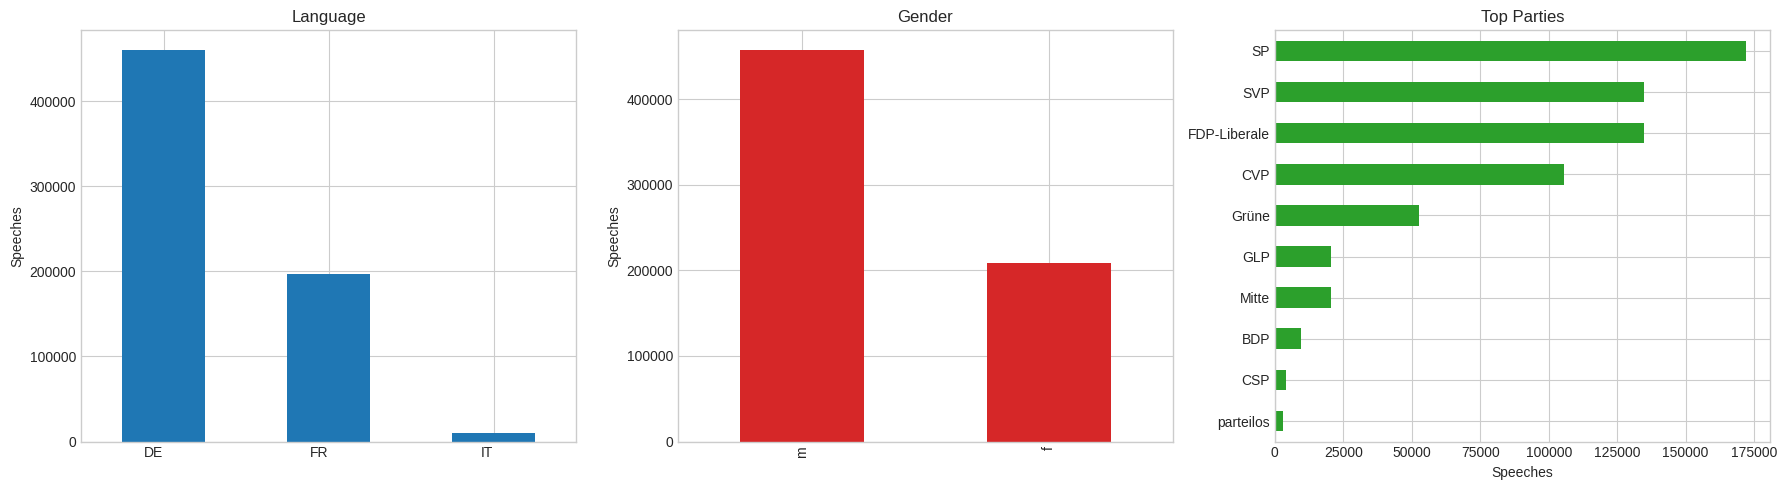

In [15]:
plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
df["language_of_text"].value_counts().plot(kind="bar", ax=axes[0], color="#1f77b4")
axes[0].set_title("Language")
axes[0].set_xlabel("")
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=0, ha="right")
axes[0].set_ylabel("Speeches")
df["gender"].value_counts().plot(kind="bar", ax=axes[1], color="#d62728")
axes[1].set_title("Gender")
axes[1].set_xlabel("")
axes[1].set_ylabel("Speeches")
df["party"].value_counts().head(10).sort_values().plot(kind="barh", ax=axes[2], color="#2ca02c")
axes[2].set_title("Top Parties")
axes[2].set_xlabel("Speeches")
axes[2].set_ylabel("")
plt.tight_layout()
plt.show()


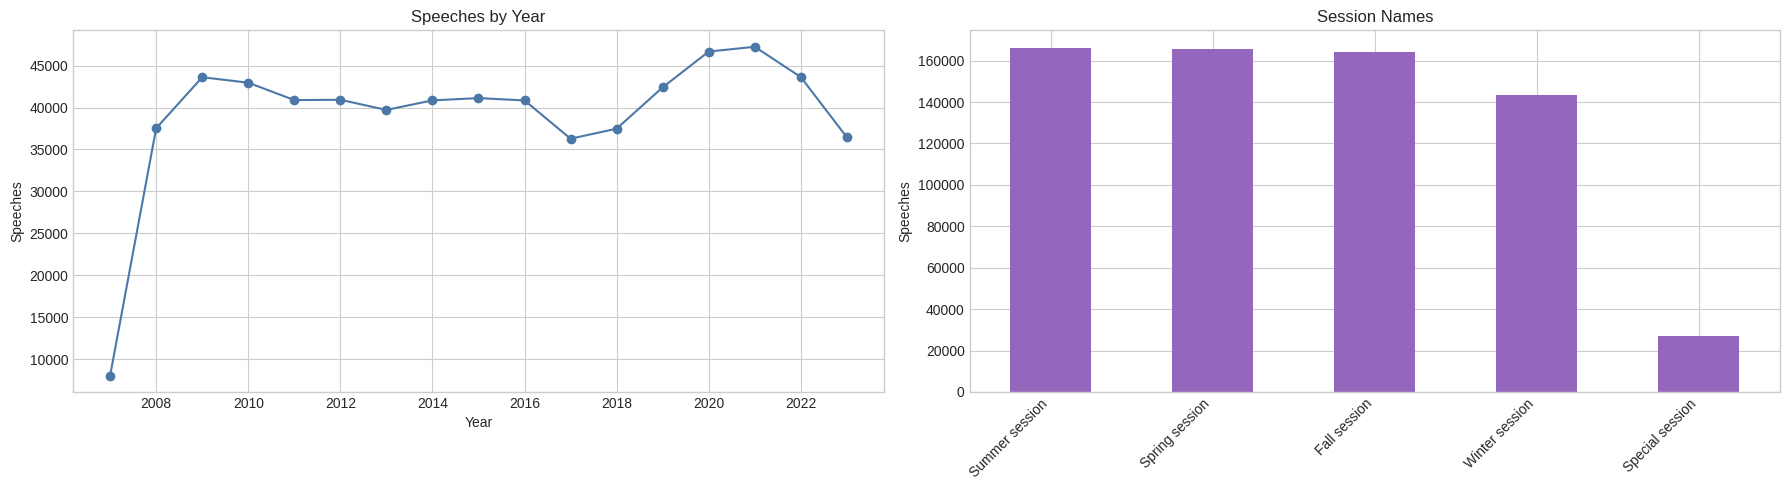

In [16]:
year_counts = df["year_int"].value_counts().sort_index()
session_counts = df["session_name"].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
year_counts.plot(ax=axes[0], marker="o", color="#4c78a8")
axes[0].set_title("Speeches by Year")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Speeches")
session_counts.plot(kind="bar", ax=axes[1], color="#9467bd")
axes[1].set_title("Session Names")
axes[1].set_xlabel("")
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha="right")
axes[1].set_ylabel("Speeches")
plt.tight_layout()
plt.show()


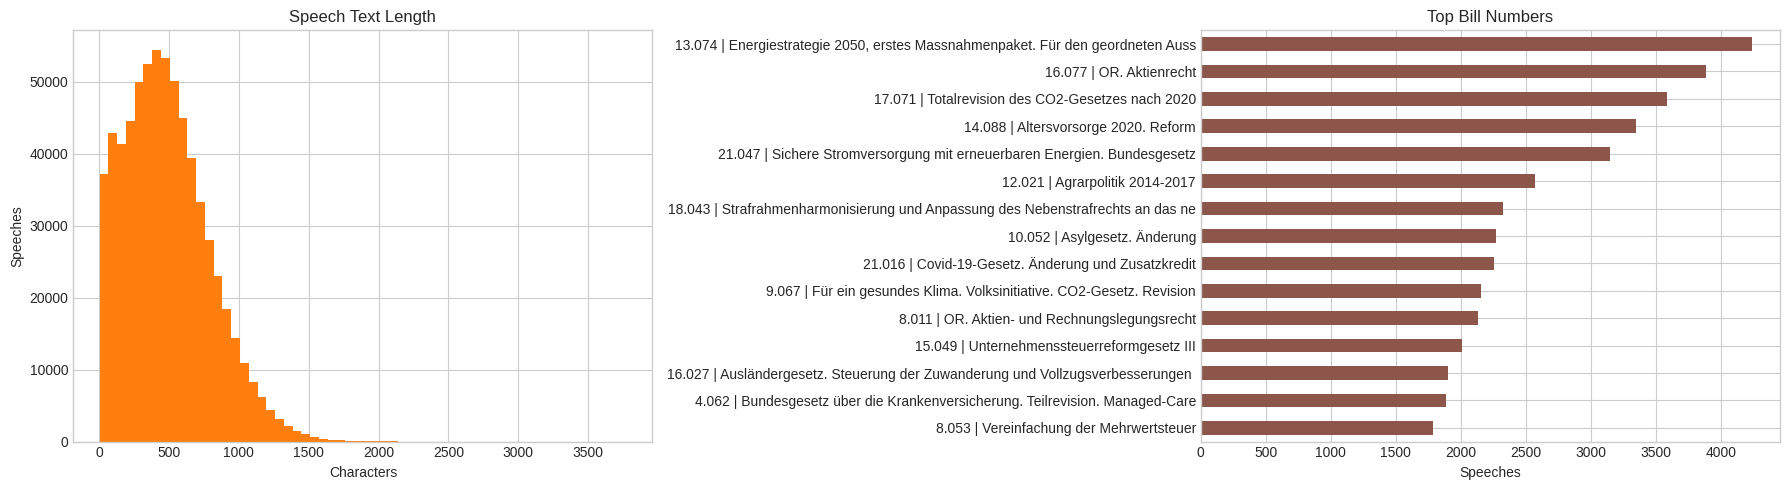

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
df["text_len"].plot(kind="hist", bins=60, ax=axes[0], color="#ff7f0e")
axes[0].set_title("Speech Text Length")
axes[0].set_xlabel("Characters")
axes[0].set_ylabel("Speeches")
axes[0].xaxis.set_major_locator(MaxNLocator(10))
bill_top = df.groupby("bill_number", dropna=True).agg(bill_title_de=("bill_title_de", lambda s: s.dropna().astype(str).mode().iat[0] if not s.dropna().empty else ""), count=("speech_id", "size")).sort_values("count", ascending=False).head(15)
bill_top["label"] = bill_top.index.map(lambda x: f"{x} | {bill_top.loc[x, 'bill_title_de'][:70]}")
bill_top.sort_values("count").plot(kind="barh", y="count", x="label", ax=axes[1], color="#8c564b", legend=False)
axes[1].set_title("Top Bill Numbers")
axes[1].set_xlabel("Speeches")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()


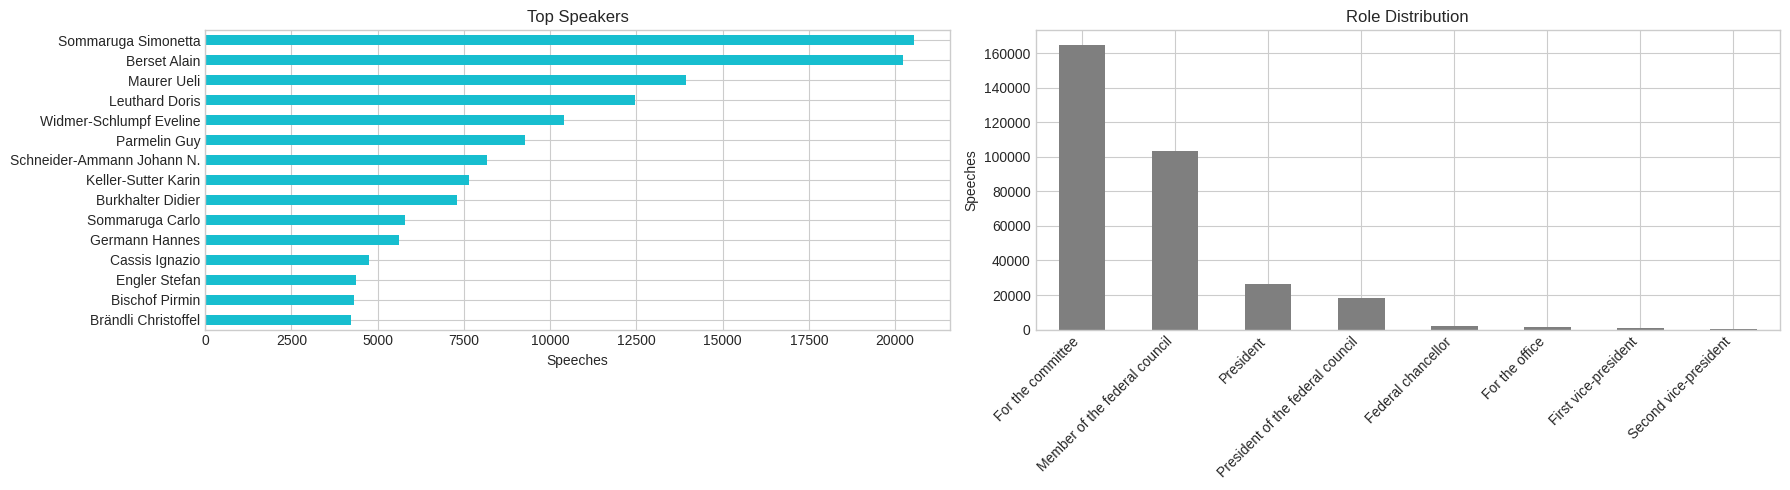

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
df["speaker_fullname"].value_counts().head(15).sort_values().plot(kind="barh", ax=axes[0], color="#17becf")
axes[0].set_title("Top Speakers")
axes[0].set_xlabel("Speeches")
axes[0].set_ylabel("")
df["role"].value_counts().head(10).plot(kind="bar", ax=axes[1], color="#7f7f7f")
axes[1].set_title("Role Distribution")
axes[1].set_xlabel("")
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha="right")
axes[1].set_ylabel("Speeches")
plt.tight_layout()
plt.show()
